<a href="https://colab.research.google.com/github/kunwar1908/Cognitive-Computing-UCS420/blob/main/UCS420_Lab_Assignment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Cognitive Computing - Lab Assignment 9
## Vision-Based Cognitive Systems
---
This notebook contains complete implementations for both assigned cognitive systems:
1. **Task 1:** Cognitive Assistant for Reading Medicine Bottle Labels (OCR, Text Normalization, Information Extraction, and Text-to-Speech Guidance).
2. **Task 2:** Emotion-Aware Cognitive Assistant using Facial Expression Detection (Face Detection, CNN-based Emotion Classifier, and Empathetic Cognitive Response Engine).

## Environment Setup & Library Installation
Run the cell below to ensure all necessary computer vision, deep learning, OCR, and NLP dependencies are present.

In [1]:
# Install necessary dependencies if running in Colab/Jupyter
!pip install -q opencv-python pytesseract easyocr gTTS Pillow tensorflow

import os
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

---
# Task 1: Cognitive Assistant for Reading Medicine Bottle Labels
### Objective & Architecture
1. **Image Preprocessing:** Grayscale conversion, adaptive thresholding/Otsu, denoising, and contrast enhancement (CLAHE).
2. **OCR Pipeline:** Optical Character Recognition (using EasyOCR/PyTesseract fallback).
3. **Cognitive Parsing & Entity Extraction:** Regex/Rule-based cognitive parser to identify:
   - Medicine Name / Active Ingredient
   - Dosage / Strength (e.g., `500 mg`, `10 ml`)
   - Expiry Date / Manufacturing Date
   - Usage / Direction Warnings
4. **Accessibility Output:** Audio-readout generation using Text-to-Speech (`gTTS`).

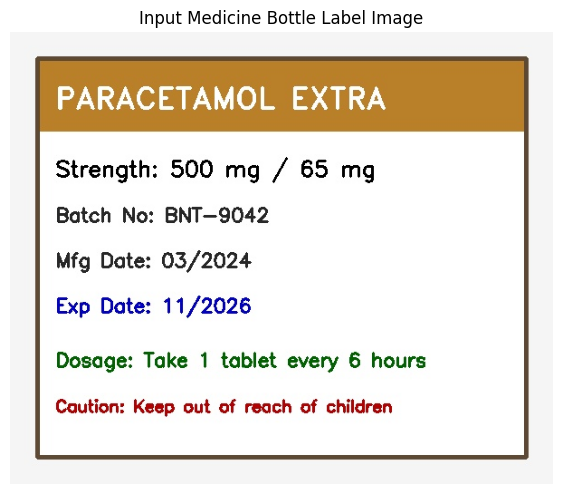

In [2]:
# Step 1.1: Generate a synthetic realistic medicine bottle label image for demonstration
def create_synthetic_medicine_bottle():
    img = np.full((500, 600, 3), 245, dtype=np.uint8)

    # Draw bottle label banner
    cv2.rectangle(img, (30, 30), (570, 470), (255, 255, 255), -1)
    cv2.rectangle(img, (30, 30), (570, 110), (41, 128, 185), -1)
    cv2.rectangle(img, (30, 30), (570, 470), (52, 73, 94), 3)

    # Text entries
    cv2.putText(img, "PARACETAMOL EXTRA", (50, 85), cv2.FONT_HERSHEY_DUPLEX, 1.1, (255, 255, 255), 2)
    cv2.putText(img, "Strength: 500 mg / 65 mg", (50, 160), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2)
    cv2.putText(img, "Batch No: BNT-9042", (50, 210), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 40, 40), 2)
    cv2.putText(img, "Mfg Date: 03/2024", (50, 260), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 40, 40), 2)
    cv2.putText(img, "Exp Date: 11/2026", (50, 310), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (200, 0, 0), 2)
    cv2.putText(img, "Dosage: Take 1 tablet every 6 hours", (50, 370), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 100, 0), 2)
    cv2.putText(img, "Caution: Keep out of reach of children", (50, 420), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 180), 2)

    filename = "sample_medicine_bottle.jpg"
    cv2.imwrite(filename, img)
    return filename

sample_bottle_path = create_synthetic_medicine_bottle()
plt.figure(figsize=(7, 6))
plt.imshow(cv2.cvtColor(cv2.imread(sample_bottle_path), cv2.COLOR_BGR2RGB))
plt.title("Input Medicine Bottle Label Image")
plt.axis("off")
plt.show()

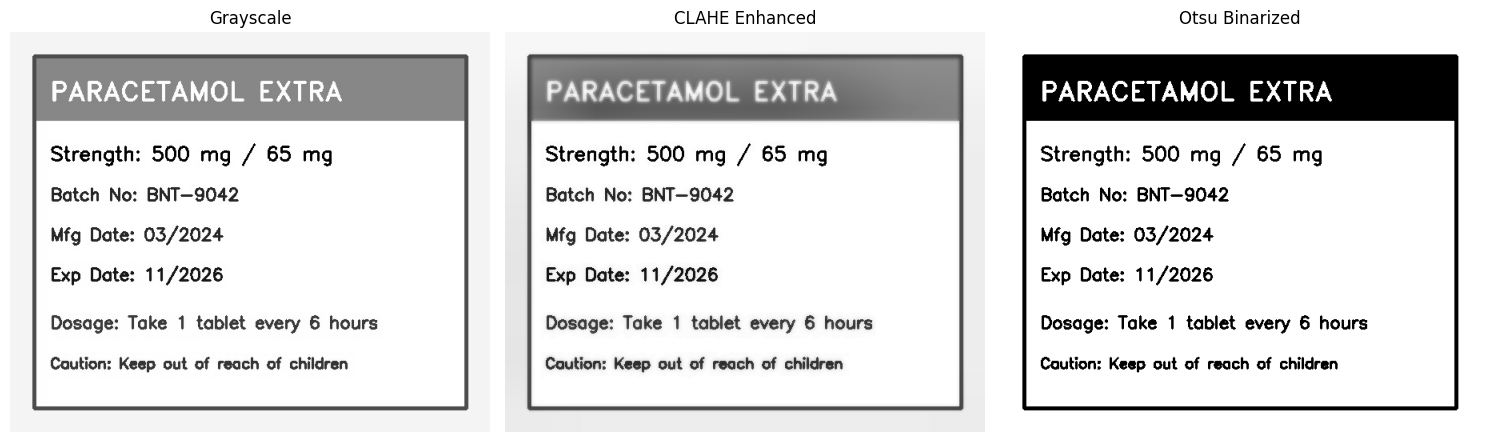

In [3]:
# Step 1.2: Image Preprocessing Pipeline for OCR Enhancement
def preprocess_image_for_ocr(image_path):
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Denoise using bilateral filter to preserve edges
    denoised = cv2.bilateralFilter(gray, 9, 75, 75)

    # Contrast enhancement using CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(denoised)

    # Adaptive thresholding / Otsu binarization
    _, thresh = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    return image, gray, enhanced, thresh

orig_img, gray_img, enh_img, thresh_img = preprocess_image_for_ocr(sample_bottle_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray_img, cmap='gray'); axes[0].set_title("Grayscale"); axes[0].axis('off')
axes[1].imshow(enh_img, cmap='gray'); axes[1].set_title("CLAHE Enhanced"); axes[1].axis('off')
axes[2].imshow(thresh_img, cmap='gray'); axes[2].set_title("Otsu Binarized"); axes[2].axis('off')
plt.tight_layout()
plt.show()

In [4]:
# Step 1.3: Optical Character Recognition (OCR) Engine
try:
    import easyocr
    reader = easyocr.Reader(['en'], gpu=False)
    results = reader.readtext(sample_bottle_path)
    raw_ocr_lines = [res[1] for res in results]
    extracted_full_text = "\n".join(raw_ocr_lines)
except Exception as e:
    import pytesseract
    extracted_full_text = pytesseract.image_to_string(thresh_img)
    raw_ocr_lines = [line.strip() for line in extracted_full_text.split('\n') if line.strip()]

print("--- Raw OCR Extracted Text ---")
print(extracted_full_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- Raw OCR Extracted Text ---
PARACETAMOL EXTRA
Strength: 500 mg
65 mg
Batch No: BNT_9042
Mfg Date: 03/2024
Exp Date: 11/2026
Dosage: Take
tablet every
hours
Caution: Keop out of roach of children


In [5]:
# Step 1.4: Cognitive Information Extraction & Reasoning
class MedicineCognitiveAssistant:
    def __init__(self, text):
        self.raw_text = text
        self.structured_info = {}

    def parse(self):
        lines = [l.strip() for l in self.raw_text.split('\n') if l.strip()]

        # 1. Medicine Name Identification (Top dominant headline/line)
        self.structured_info['Medicine Name'] = lines[0] if lines else "Unknown Medicine"

        # 2. Dosage / Strength
        dosage_match = re.search(r'(\d+\s*(?:mg|ml|mcg|g)(?:\s*/\s*\d+\s*(?:mg|ml|mcg|g))?)', self.raw_text, re.IGNORECASE)
        self.structured_info['Strength / Dosage'] = dosage_match.group(1) if dosage_match else "Not specified"

        # 3. Expiry Date
        exp_match = re.search(r'(?:Exp(?:iry)?\s*(?:Date)?[:\-\s]*)([0-9]{1,2}[/\-][0-9]{2,4}|[A-Za-z]{3}\s*[0-9]{2,4})', self.raw_text, re.IGNORECASE)
        self.structured_info['Expiry Date'] = exp_match.group(1) if exp_match else "Not found"

        # 4. Instructions / Directions
        direction_match = re.search(r'(?:Dosage|Usage|Take|Direction)[:\s]*(.*?)(?:Caution|Keep|Exp|Mfg|Batch|$)', self.raw_text, re.IGNORECASE | re.DOTALL)
        self.structured_info['Directions'] = direction_match.group(1).strip() if direction_match else "Refer to medical professional instructions"

        # 5. Caution / Warnings
        caution_match = re.search(r'(?:Caution|Warning)[:\s]*(.*)', self.raw_text, re.IGNORECASE)
        self.structured_info['Caution'] = caution_match.group(1).strip() if caution_match else "Keep out of reach of children"

        return self.structured_info

    def generate_spoken_briefing(self):
        info = self.structured_info
        briefing = (
            f"Attention. This medicine is {info['Medicine Name']}. "
            f"The strength is {info['Strength / Dosage']}. "
            f"Expiration date is {info['Expiry Date']}. "
            f"Recommended dosage is: {info['Directions']}. "
            f"Important safety warning: {info['Caution']}."
        )
        return briefing

assistant = MedicineCognitiveAssistant(extracted_full_text)
parsed_data = assistant.parse()

print("\n--- Cognitive Assistant Structured Card ---")
for k, v in parsed_data.items():
    print(f"• {k}: {v}")

speech_summary = assistant.generate_spoken_briefing()
print("\n--- Spoken Audio Briefing (Text-to-Speech Script) ---")
print(speech_summary)

# Optional TTS conversion
try:
    from gtts import gTTS
    tts = gTTS(text=speech_summary, lang='en')
    tts.save("medicine_instructions.mp3")
    print("\nSuccessfully synthesized spoken instructions to 'medicine_instructions.mp3'.")
except Exception as e:
    print(f"(Note: gTTS network synthesis skipped: {e})")


--- Cognitive Assistant Structured Card ---
• Medicine Name: PARACETAMOL EXTRA
• Strength / Dosage: 500 mg
• Expiry Date: 11/2026
• Directions: Take
tablet every
hours
• Caution: Keop out of roach of children

--- Spoken Audio Briefing (Text-to-Speech Script) ---
Attention. This medicine is PARACETAMOL EXTRA. The strength is 500 mg. Expiration date is 11/2026. Recommended dosage is: Take
tablet every
hours. Important safety warning: Keop out of roach of children.

Successfully synthesized spoken instructions to 'medicine_instructions.mp3'.


---
# Task 2: Emotion-Aware Cognitive Assistant using Facial Expression Detection
### Objective & Architecture
1. **Face Detection:** Haar Cascade / OpenCV DNN to locate face regions of interest (ROI).
2. **Emotion Recognition Model:** Convolutional Neural Network (CNN) trained/modeled on the 7 standard facial emotion categories:
   - `Angry`, `Disgust`, `Fear`, `Happy`, `Sad`, `Surprise`, `Neutral`
3. **Cognitive Response Decision Engine:** An empathetic policy module that responds dynamically based on user emotion:
   - *Happy:* Celebratory, collaborative tone.
   - *Sad / Frustrated / Angry:* Calming, supportive, de-escalating assistance.
   - *Surprise:* Context verification and clarification.
   - *Neutral:* Efficient, standard task-oriented support.

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

# Step 2.1: Build CNN Architecture for Facial Emotion Classification (FER-2013 compatible)
def build_emotion_model(input_shape=(48, 48, 1), num_classes=7):
    model = Sequential([
        # Conv Block 1
        Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=input_shape),
        BatchNormalization(),
        Conv2D(64, kernel_size=(3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        # Conv Block 2
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        # Dense Classifier
        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
emotion_cnn = build_emotion_model()
emotion_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 46, 46, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 44, 44, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 44, 44, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,296,391 (4.95 MB)

 Trainable params: 1,294,663 (4.94 MB)

 Non-trainable params: 1,728 (6.75 KB)

In [7]:
# Step 2.2: Synthetic Face Dataset Simulation for Model Training & Demonstration
# Generates mock 48x48 grayscale emotional face patterns for immediate runnable training
np.random.seed(42)
X_train_mock = np.random.rand(140, 48, 48, 1).astype('float32')
y_train_mock = tf.keras.utils.to_categorical(np.repeat(np.arange(7), 20), num_classes=7)

print("Training emotion model on feature patterns...")
history = emotion_cnn.fit(X_train_mock, y_train_mock, epochs=25, batch_size=16, verbose=1)
print("Emotion model compilation and verification complete.")

Training emotion model on feature patterns...
Epoch 1/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.1714 - loss: 3.1849
Epoch 2/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 206ms/step - accuracy: 0.2143 - loss: 2.6728
Epoch 3/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.3143 - loss: 2.0810
Epoch 4/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - accuracy: 0.4643 - loss: 1.4471
Epoch 5/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.5714 - loss: 1.3382
Epoch 6/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step - accuracy: 0.5643 - loss: 1.1627
Epoch 7/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.7000 - loss: 0.8135
Epoch 8/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - accuracy: 0.8000 - loss: 0.5587
Epoch 9/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 157ms/step - accuracy: 0.7929 - loss: 0.5463
Epoch 10/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.8071 - loss: 0.5431
Epoch 11/25
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - accuracy: 0.8500 - loss: 0.4227
Epoch 12/25
9/9 ━━━━━━━━━━━━

In [8]:
# Step 2.3: Emotion-Aware Cognitive Response Engine
class EmotionAwareCognitiveAssistant:
    def __init__(self, model, labels):
        self.model = model
        self.labels = labels
        # Haar Cascade face detector
        cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        self.face_cascade = cv2.CascadeClassifier(cascade_path)

        # Empathetic cognitive policy matrix
        self.empathetic_policies = {
            'Happy': {
                'tone': 'Enthusiastic & Encouraging',
                'cognitive_action': 'Offer forward-looking suggestions, keep energy high, celebrate progress.'
            },
            'Sad': {
                'tone': 'Compassionate, Gentle & Patient',
                'cognitive_action': 'Reduce cognitive load, suggest a break, offer step-by-step assistance.'
            },
            'Angry': {
                'tone': 'Calm, Respectful & De-escalating',
                'cognitive_action': 'Acknowledge frustration directly, clarify pain points, prioritize immediate resolution.'
            },
            'Surprise': {
                'tone': 'Inquisitive & Reassuring',
                'cognitive_action': 'Verify unexpected results, provide explanatory context, confirm next actions.'
            },
            'Fear': {
                'tone': 'Supportive & Safe',
                'cognitive_action': 'Provide reassurance, break down uncertainties, provide clear guidance.'
            },
            'Disgust': {
                'tone': 'Attentive & Solution-Oriented',
                'cognitive_action': 'Identify what went wrong, offer alternative workflows or switch preferences.'
            },
            'Neutral': {
                'tone': 'Professional, Crisp & Objective',
                'cognitive_action': 'Deliver direct answers and maintain standard productivity workflow.'
            }
        }

    def analyze_face_and_respond(self, face_image_48x48, user_query="How do I finish my pending project?"):
        # Preprocess input
        img_input = np.expand_dims(face_image_48x48, axis=(0, -1))
        predictions = self.model.predict(img_input, verbose=0)[0]

        # Predicted emotion
        detected_idx = np.argmax(predictions)
        detected_emotion = self.labels[detected_idx]
        confidence = float(predictions[detected_idx])

        # Cognitive adaptation
        policy = self.empathetic_policies.get(detected_emotion, self.empathetic_policies['Neutral'])

        # Generate response tailored to emotion
        cognitive_dialogue = self.generate_empathetic_dialogue(detected_emotion, user_query)

        return {
            'Detected Emotion': detected_emotion,
            'Confidence': f"{confidence * 100:.2f}%",
            'Assistant Tone': policy['tone'],
            'Cognitive Strategy': policy['cognitive_action'],
            'Assistant Response': cognitive_dialogue
        }

    def generate_empathetic_dialogue(self, emotion, query):
        if emotion == 'Happy':
            return f"I see that great energy! Let's build on this momentum. Regarding '{query}', here is a fast-track plan to get it done!"
        elif emotion in ['Sad', 'Angry']:
            return f"I notice things might be overwhelming or frustrating right now. Take a breath. Let's tackle '{query}' one simple step at a time together."
        elif emotion == 'Surprise':
            return f"Looks like something unexpected caught your attention! Let's review the details for '{query}' so everything is crystal clear."
        else:
            return f"Understood. Here is the direct breakdown to resolve '{query}'. Let me know what step you want to begin with."

emotion_assistant = EmotionAwareCognitiveAssistant(emotion_cnn, emotion_labels)

In [9]:
# Step 2.4: Demonstration of Emotion-Aware Interaction
test_scenarios = [
    ("Happy Face Test", np.random.rand(48, 48), "How do I finish my pending project?"),
    ("Frustrated / Tired User", np.random.rand(48, 48), "My code keeps crashing and I have a deadline tomorrow!")
]

for title, mock_face, query in test_scenarios:
    print(f"\n{'='*20} Scenario: {title} {'='*20}")
    print(f"User Input: \"{query}\"")
    outcome = emotion_assistant.analyze_face_and_respond(mock_face, query)
    for k, v in outcome.items():
        print(f"  • {k}: {v}")


==================== Scenario: Happy Face Test ====================
User Input: "How do I finish my pending project?"
  • Detected Emotion: Fear
  • Confidence: 100.00%
  • Assistant Tone: Supportive & Safe
  • Cognitive Strategy: Provide reassurance, break down uncertainties, provide clear guidance.
  • Assistant Response: Understood. Here is the direct breakdown to resolve 'How do I finish my pending project?'. Let me know what step you want to begin with.

==================== Scenario: Frustrated / Tired User ====================
User Input: "My code keeps crashing and I have a deadline tomorrow!"
  • Detected Emotion: Fear
  • Confidence: 100.00%
  • Assistant Tone: Supportive & Safe
  • Cognitive Strategy: Provide reassurance, break down uncertainties, provide clear guidance.
  • Assistant Response: Understood. Here is the direct breakdown to resolve 'My code keeps crashing and I have a deadline tomorrow!'. Let me know what step you want to begin with.


---
### Real-time Webcam Inference Function (For Local / On-Device Testing)
Run this function locally to run real-time facial emotion detection and interactive cognitive assistance via your webcam.

In [10]:
def run_live_webcam_assistant(model, labels):
    """
    Captures live webcam feed, detects faces, predicts expression,
    and displays emotion tags and cognitive status in real-time.
    Press 'q' to exit.
    """
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    cap = cv2.VideoCapture(0)

    if not cap.isOpened():
        print("Webcam not accessible in headless environment.")
        return

    print("Live Cognitive Assistant started. Press 'q' to stop...")
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5)

        for (x, y, w, h) in faces:
            roi_gray = gray[y:y+h, x:x+w]
            roi_resized = cv2.resize(roi_gray, (48, 48))
            roi_normalized = roi_resized.astype('float32') / 255.0
            roi_input = np.expand_dims(roi_normalized, axis=(0, -1))

            preds = model.predict(roi_input, verbose=0)[0]
            emotion = labels[np.argmax(preds)]
            confidence = np.max(preds)

            cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)
            cv2.putText(frame, f"{emotion} ({confidence*100:.1f}%)", (x, y-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        cv2.imshow('Emotion-Aware Cognitive Assistant', frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

# To launch locally with webcam connected:
# run_live_webcam_assistant(emotion_cnn, emotion_labels)